# Week 3 — Netflix Content Pattern Analysis
**Sahana Viyani A | 25BAD092**

Original code separated from the combined notebook.

**Run Week 2 first:** This notebook expects `df` from Week 2. To run independently, load `netflix_titles.csv` into `df` before running the analysis.

In [ ]:
import pandas as pd
import os
if 'df' not in globals():
    path = '/content/netflix_data/netflix_titles.csv' if os.path.exists('/content/netflix_data/netflix_titles.csv') else 'netflix_titles.csv'
    df = pd.read_csv(path)

In [ ]:
# WEEK 3

# The Cleaning Sprint — Handling Missing Values (Imputation strategies) and Outlier Detection (Boxplots/Z-score).

In [15]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import zipfile

sns.set_theme(style="whitegrid")

In [16]:
# Check Missing Values
missing = df.isnull().sum()

print(missing)

show_id            0
type               0
title              0
director        2634
cast             825
country          831
date_added        10
release_year       0
rating             4
duration           3
listed_in          0
description        0
dtype: int64


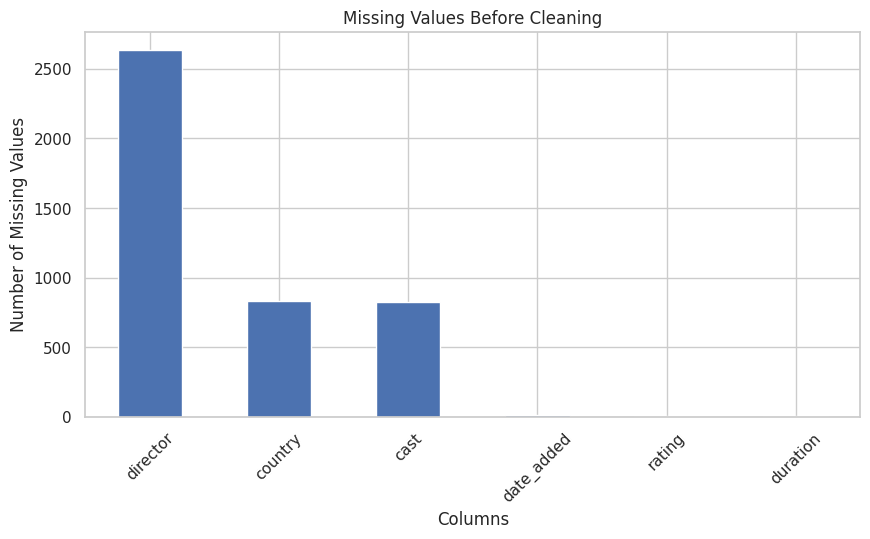

In [17]:
# Visualize missing values
plt.figure(figsize=(10,5))

missing[missing > 0].sort_values(ascending=False).plot(kind='bar')

plt.title('Missing Values Before Cleaning')
plt.xlabel('Columns')
plt.ylabel('Number of Missing Values')
plt.xticks(rotation=45)

plt.show()

In [18]:
#Handle Missing Values
cleaned_df = df.copy()

cleaned_df['director'] = cleaned_df['director'].fillna('Unknown')
cleaned_df['cast'] = cleaned_df['cast'].fillna('Unknown')
cleaned_df['country'] = cleaned_df['country'].fillna('Unknown')

cleaned_df['rating'] = cleaned_df['rating'].fillna(cleaned_df['rating'].mode()[0])
cleaned_df['duration'] = cleaned_df['duration'].fillna('Unknown')
cleaned_df['date_added'] = cleaned_df['date_added'].fillna('Unknown')

In [19]:
before = df.isnull().sum()
after = cleaned_df.isnull().sum()

comparison = pd.DataFrame({
    'Before Cleaning': before,
    'After Cleaning': after
})

comparison = comparison[comparison['Before Cleaning'] > 0]

print(comparison)

            Before Cleaning  After Cleaning
director               2634               0
cast                    825               0
country                 831               0
date_added               10               0
rating                    4               0
duration                  3               0


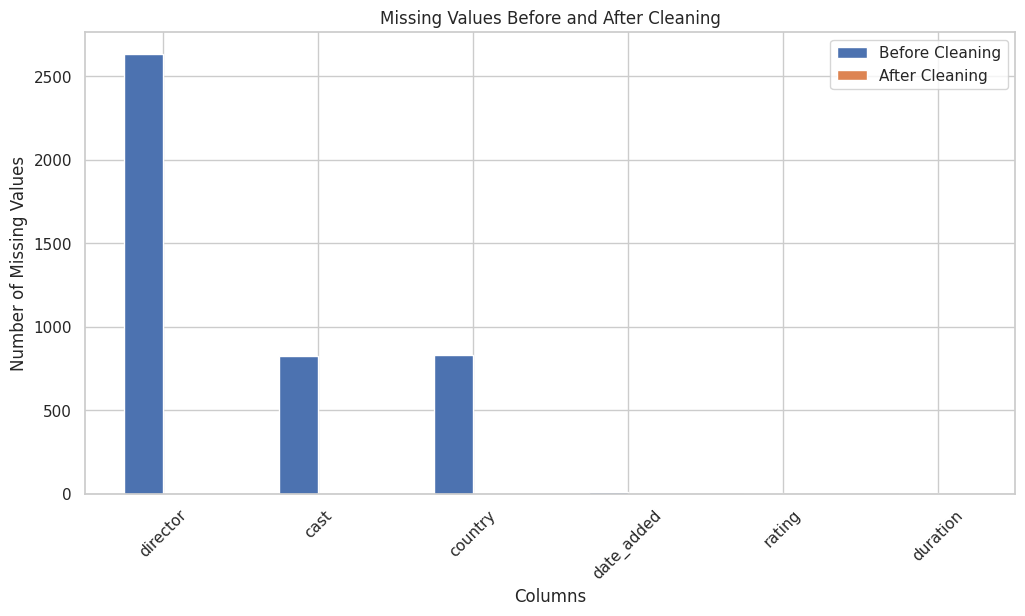

In [20]:
comparison.plot(kind='bar', figsize=(12,6))

plt.title('Missing Values Before and After Cleaning')
plt.xlabel('Columns')
plt.ylabel('Number of Missing Values')
plt.xticks(rotation=45)

plt.show()

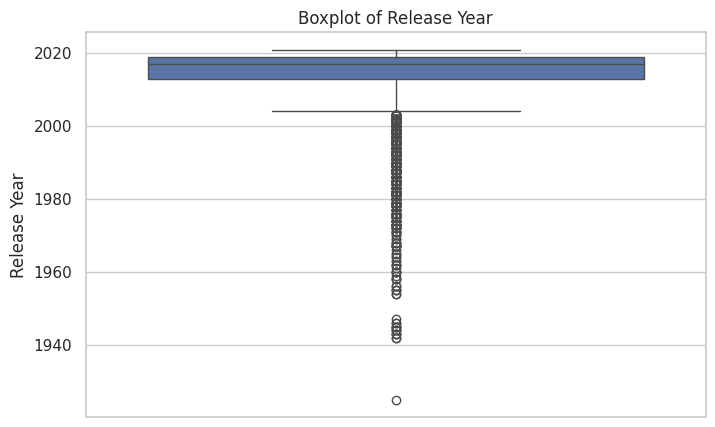

In [21]:
plt.figure(figsize=(8,5))

sns.boxplot(y=cleaned_df['release_year'])

plt.title('Boxplot of Release Year')
plt.ylabel('Release Year')

plt.show()

In [22]:
from scipy.stats import zscore

z_scores = np.abs(zscore(cleaned_df['release_year']))

outliers = cleaned_df[z_scores > 3]

print("Number of outliers:", len(outliers))

Number of outliers: 217


In [23]:
# Final Cleaning Check
print("Missing values after cleaning:")
print(cleaned_df.isnull().sum())

print("\nDuplicate rows:", cleaned_df.duplicated().sum())

Missing values after cleaning:
show_id         0
type            0
title           0
director        0
cast            0
country         0
date_added      0
release_year    0
rating          0
duration        0
listed_in       0
description     0
dtype: int64

Duplicate rows: 0


In [ ]:
# Week 3 – Cleaning and Visualization Summary

#Missing values were identified and visualized using Pandas and Matplotlib.
#Categorical missing values were handled using "Unknown", while the mode was
#used for the missing rating values.

#Before-and-after visualizations were created to compare the missing-value
#status.

#A boxplot and Z-score method were used to inspect potential outliers in the
#release_year variable.

#The cleaned dataset is now prepared for further EDA.